In [ ]:
import pandas as pd
import nltk
import numpy as np
import re
from nltk.stem import wordnet # to perform lemmitization
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer # to perfor bow
from sklearn.feature_extraction.text import TfidfVectorizer # to perfor bow
from nltk import pos_tag # for parts of speech
from sklearn.metrics import pairwise_distances # to perform cosine similarity
from nltk import word_tokenize # to create tokens
from nltk.corpus import stopwords # for stop words

In [ ]:
# Download nltk data libraries. All can be downloaded by using nltk.download('all')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
# nltk.download('all')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [ ]:
pip install --upgrade nltk


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.0 MB/s eta 0:00:00
  Attempting uninstall: nltk
    Found existing installation: nltk 3.9.1
    Uninstalling nltk-3.9.1:
      Successfully uninstalled nltk-3.9.1


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/SEM-6/Mini-Project/dataset.csv")


In [ ]:
df.head(5)


,scheme_name,slug,details,benefits,eligibility,application,documents,level,schemeCategory,Unnamed: 9,tags
0,"""Immediate Relief Assistance"" under ""Welfare a...",ira-wrflsncs,"The scheme ""Immediate Relief Assistance"" is a ...","₹ 1,00,000, in two installments of ₹ 50,000 ea...",The applicant should be the family (legal heir...,Step 1: The interested applicant should visit ...,Photograph of the Family (Legal Heir) of the M...,State,"Agriculture,Rural & Environment, Social welfar...",NaN,"Missing, Fisherman, Relief, Financial Assistan..."
1,AICTE SHORT TERM TRAINING PROGRAMME-SFURTI SCHEME,astpss,"Short Term Training Programme-SFURTI Program, ...","Financial Assistance : Limit of funding ₹ 4,00...",The institution should be AICTE approved.,Registration of New Institute: Step 01: Visit ...,Feedback Form Copy of Proceedings Completion R...,Central,Education & Learning,NaN,"Trainings, Financial Assistance, AICTE"
2,Burial and Ex-gratia Payment Scheme in Case of...,baepsicodouldwact,"Launched in 2014, the "" Burial and Ex-gratia P...","Funeral Assistance: ₹3,000 payable in case of ...",The deceased construction worker should have b...,Step 1: The interested applicant should visit ...,Aadhaar Card of the applicant (nominee/Legal h...,State,Social welfare & Empowerment,NaN,"Building Worker, Construction Workers, Unregis..."
3,Consortia & Tender Marketing Scheme,ctms,Promotion of the product of Micro and Small En...,Enlistment of the Unit for participating in Go...,Micro & Small Enterprises registered with NSIC...,"Step 01: The application form, in the prescrib...",A passport size photograph of each of the Prop...,Central,Business & Entrepreneurship,NaN,"Goods And Services Marketing, Turnkey Projects..."
4,Garuda Scheme for Funeral Expense,gsfe,Andhra Pradesh Brahmin Welfare Corporation (AB...,"Financial Assistance of ₹10,000/- for funeral ...",The applicant should be a close relative of th...,Registration and apply Step 01: Applicants hav...,Passport-size Photograph of the Applicant Aadh...,State,Social welfare & Empowerment,NaN,"Social Welfare, Financial Assistance, Deceased..."


In [ ]:
df.shape[0] # Returns the number of rows in dataset


3400

In [ ]:
df.isnull().sum()


,0
scheme_name,0
slug,0
details,0
benefits,0
eligibility,0
application,2
documents,11
level,0
schemeCategory,0
Unnamed: 9,3400


In [ ]:
# Drop unwanted column
df.drop(columns=["Unnamed: 9"], inplace=True)

print("Unnecessary column removed")


Unnecessary column removed


In [ ]:
# Fill missing textual fields
df["application"].fillna("", inplace=True)
df["documents"].fillna("", inplace=True)
df["tags"].fillna("", inplace=True)

print("Missing textual values handled successfully")


Missing textual values handled successfully


/tmp/ipykernel_1433/1953936121.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["application"].fillna("", inplace=True)
/tmp/ipykernel_1433/1953936121.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 

In [ ]:
df.isnull().sum()


,0
scheme_name,0
slug,0
details,0
benefits,0
eligibility,0
application,0
documents,0
level,0
schemeCategory,0
tags,0


In [ ]:

df["combined_text"] = (
    df["scheme_name"] + " " +
    df["details"] + " " +
    df["benefits"] + " " +
    df["eligibility"] + " " +
    df["tags"]
)


In [ ]:
# 🔹 1. Define your custom domain keywords to KEEP
important_keywords = {"benefit", "loan", "assistance", "support", "eligible", "scheme", "financial", "application"}


In [ ]:
# 🔹 2. Get standard English stopwords
default_stopwords = set(stopwords.words("english"))

In [ ]:
# 🔹 3. Remove domain-specific words from the stopword list
custom_stopwords = default_stopwords - important_keywords

In [ ]:

# 🔹 4. Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

In [ ]:

# 🔹 5. Update clean_text() function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    tokens = text.split()
    tokens = [word for word in tokens if word not in custom_stopwords]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(tokens)


In [ ]:
df["cleaned_text"] = df["combined_text"].apply(clean_text)

df[["cleaned_text", "schemeCategory"]].head()


,cleaned_text,schemeCategory
0,immediate relief assistance welfare relief fis...,"Agriculture,Rural & Environment, Social welfar..."
1,aicte short term training programmesfurti sche...,Education & Learning
2,burial exgratia payment scheme case death unre...,Social welfare & Empowerment
3,consortium tender marketing scheme promotion p...,Business & Entrepreneurship
4,garuda scheme funeral expense andhra pradesh b...,Social welfare & Empowerment


In [ ]:
print("Unique categories BEFORE mapping:", df['schemeCategory'].nunique())
print(df['schemeCategory'].unique())




Unique categories BEFORE mapping: 210
['Agriculture,Rural & Environment, Social welfare & Empowerment'
 'Education & Learning' 'Social welfare & Empowerment'
 'Business & Entrepreneurship' 'Women and Child' 'Health & Wellness'
 'Skills & Employment'
 'Agriculture,Rural & Environment, Banking,Financial Services and Insurance'
 'Agriculture,Rural & Environment'
 'Business & Entrepreneurship, Science, IT & Communications'
 'Business & Entrepreneurship, Skills & Employment'
 'Business & Entrepreneurship, Agriculture,Rural & Environment'
 'Business & Entrepreneurship, Transport & Infrastructure'
 'Business & Entrepreneurship, Social welfare & Empowerment'
 'Skills & Employment, Business & Entrepreneurship'
 'Banking,Financial Services and Insurance, Social welfare & Empowerment'
 'Education & Learning, Transport & Infrastructure'
 'Education & Learning, Social welfare & Empowerment'
 'Education & Learning, Travel & Tourism'
 'Women and Child, Social welfare & Empowerment'
 'Science, IT & Co

In [ ]:
# After mapping
print("Unique categories AFTER mapping:", df['schemeCategory'].nunique())
print(df['schemeCategory'].unique())

Unique categories AFTER mapping: 210
['Agriculture,Rural & Environment, Social welfare & Empowerment'
 'Education & Learning' 'Social welfare & Empowerment'
 'Business & Entrepreneurship' 'Women and Child' 'Health & Wellness'
 'Skills & Employment'
 'Agriculture,Rural & Environment, Banking,Financial Services and Insurance'
 'Agriculture,Rural & Environment'
 'Business & Entrepreneurship, Science, IT & Communications'
 'Business & Entrepreneurship, Skills & Employment'
 'Business & Entrepreneurship, Agriculture,Rural & Environment'
 'Business & Entrepreneurship, Transport & Infrastructure'
 'Business & Entrepreneurship, Social welfare & Empowerment'
 'Skills & Employment, Business & Entrepreneurship'
 'Banking,Financial Services and Insurance, Social welfare & Empowerment'
 'Education & Learning, Transport & Infrastructure'
 'Education & Learning, Social welfare & Empowerment'
 'Education & Learning, Travel & Tourism'
 'Women and Child, Social welfare & Empowerment'
 'Science, IT & Com

In [ ]:
# Define your mapping dictionary
category_mapping = {
    "education & learning": "education",
    "skills & employment": "employment",
    "health & wellness": "health",
    "social welfare & empowerment": "social welfare",
    "business & entrepreneurship": "entrepreneurship",
    "banking,financial services and insurance": "finance",
    "women and child": "women",
    "housing & shelter": "housing",
    "utility & sanitation": "sanitation",
    "transport & infrastructure": "infrastructure",
    "science, it & communications": "technology",
    "sports & culture": "sports",
    "travel & tourism": "tourism",
    "public safety,law & justice": "public safety",
    "agriculture,rural & environment": "agriculture"
}

# Helper: clean & map single category string
def map_category(raw_string):
    # lowercase, strip, split
    parts = [p.strip().lower() for p in raw_string.split(",")]
    mapped = set()
    for part in parts:
        for key in category_mapping:
            if key in part:
                mapped.add(category_mapping[key])
    return ", ".join(sorted(mapped)) if mapped else "other"

# Apply mapping
df['normalized_category'] = df['schemeCategory'].apply(map_category)

# Check results
print("Unique cleaned categories:", df['normalized_category'].nunique())
print(df['normalized_category'].value_counts())


Unique cleaned categories: 83
normalized_category
social welfare                                  701
education                                       590
other                                           488
entrepreneurship                                411
social welfare, women                           185
                                               ... 
health, sanitation, social welfare, women         1
entrepreneurship, housing, social welfare         1
entrepreneurship, social welfare, sports          1
education, employment, social welfare, women      1
housing, infrastructure, social welfare           1
Name: count, Length: 83, dtype: int64


In [ ]:
processed_df = df[["cleaned_text", "normalized_category"]]
processed_df.rename(columns={"normalized_category": "schemeCategory"}, inplace=True)

processed_df.to_csv("processed_schemes.csv", index=False)

print("✅ Cleaned data saved successfully with normalized categories!")


✅ Cleaned data saved successfully with normalized categories!


/tmp/ipykernel_1433/1706092222.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  processed_df.rename(columns={"normalized_category": "schemeCategory"}, inplace=True)


In [ ]:
import pandas as pd

df = pd.read_csv("processed_schemes.csv")

df.head()


,cleaned_text,schemeCategory
0,immediate relief assistance welfare relief fis...,social welfare
1,aicte short term training programmesfurti sche...,education
2,burial exgratia payment scheme case death unre...,social welfare
3,consortium tender marketing scheme promotion p...,entrepreneurship
4,garuda scheme funeral expense andhra pradesh b...,social welfare


In [ ]:
pip install sentence-transformers


In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report
import pandas as pd

In [ ]:
# 1. Load cleaned dataset
df = pd.read_csv("processed_schemes.csv")

# 2. Sentence-BERT vector embeddings
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")
X = sbert_model.encode(df["cleaned_text"], convert_to_numpy=True)

# 3. Convert category strings → label list
df['label_list'] = df['schemeCategory'].apply(lambda x: [cat.strip() for cat in x.split(',')])


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

ValueError: Unsupported input type: Series. Expected one of: str, dict, PIL.Image.Image, np.ndarray, torch.Tensor

In [ ]:
# 4. Multi-label binarization
mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(df['label_list'])
print("Classes:", mlb.classes_)

Classes: ['education' 'employment' 'entrepreneurship' 'health' 'housing'
 'infrastructure' 'other' 'sanitation' 'social welfare' 'sports' 'tourism'
 'women']


In [ ]:
import joblib

# Save label binarizer
joblib.dump(mlb, "label_binarizer.pkl")
print("✅ Label binarizer saved successfully!")


✅ Label binarizer saved successfully!


In [ ]:
from google.colab import files
files.download("label_binarizer.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 5. Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


In [ ]:
# 6. Train multi-label classifier
classifier = OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced"))
classifier.fit(X_train, Y_train)


OneVsRestClassifier(estimator=LogisticRegression(class_weight='balanced',
                                                 max_iter=1000))

In [ ]:
# 7. Evaluate
Y_pred = classifier.predict(X_test)
print("Classification Report:\n")
print(classification_report(Y_test, Y_pred, target_names=mlb.classes_))

Classification Report:

                  precision    recall  f1-score   support

       education       0.85      0.93      0.89       159
      employment       0.48      0.80      0.60        61
entrepreneurship       0.68      0.91      0.78       105
          health       0.45      0.89      0.59        46
         housing       0.45      0.90      0.60        21
  infrastructure       0.18      0.71      0.29        14
           other       0.76      0.94      0.84       109
      sanitation       0.18      0.62      0.28         8
  social welfare       0.73      0.81      0.77       248
          sports       0.64      0.92      0.75        25
         tourism       0.20      0.80      0.32         5
           women       0.51      0.92      0.66        61

       micro avg       0.62      0.87      0.73       862
       macro avg       0.51      0.85      0.61       862
    weighted avg       0.67      0.87      0.75       862
     samples avg       0.70      0.90      0.7

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


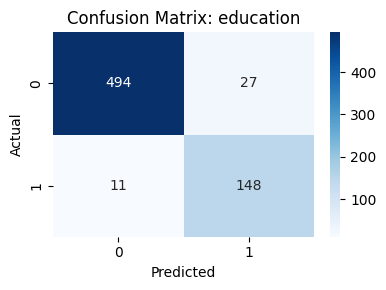

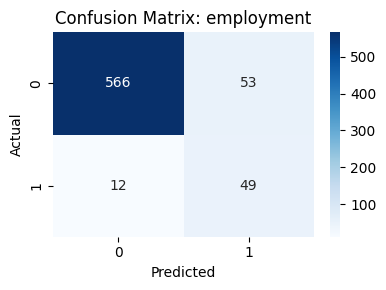

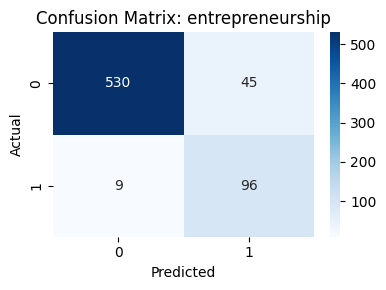

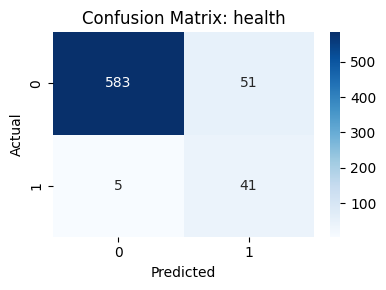

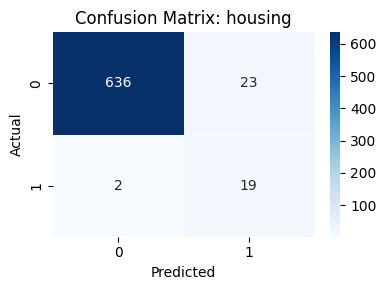

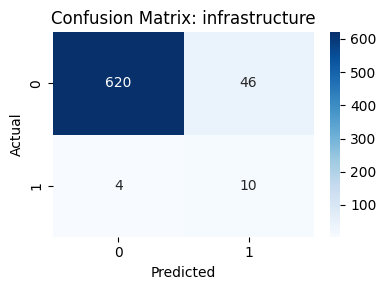

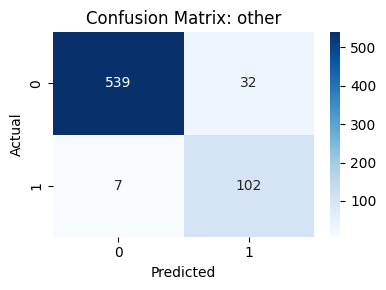

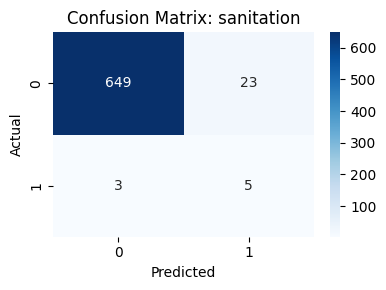

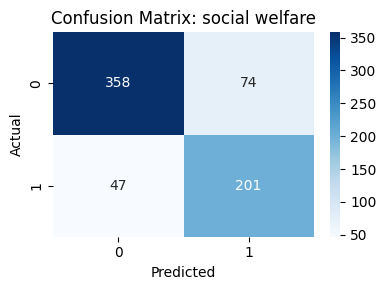

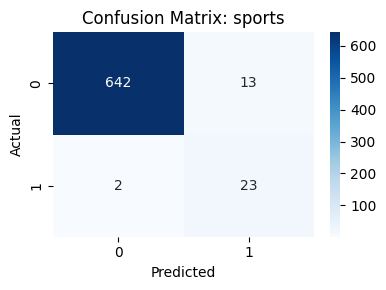

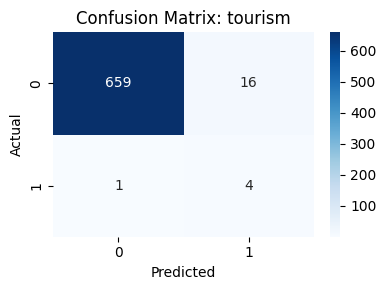

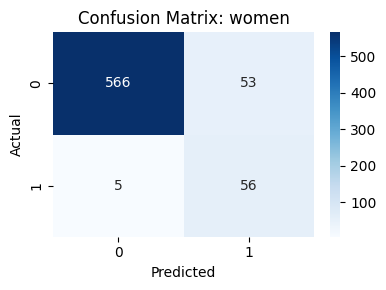

In [ ]:
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

for i, label in enumerate(mlb.classes_):
    cm = confusion_matrix(Y_test[:, i], Y_pred[:, i])
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix: {label}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


In [ ]:
print(classification_report(Y_test, Y_pred, target_names=mlb.classes_))


                  precision    recall  f1-score   support

       education       0.85      0.93      0.89       159
      employment       0.48      0.80      0.60        61
entrepreneurship       0.68      0.91      0.78       105
          health       0.45      0.89      0.59        46
         housing       0.45      0.90      0.60        21
  infrastructure       0.18      0.71      0.29        14
           other       0.76      0.94      0.84       109
      sanitation       0.18      0.62      0.28         8
  social welfare       0.73      0.81      0.77       248
          sports       0.64      0.92      0.75        25
         tourism       0.20      0.80      0.32         5
           women       0.51      0.92      0.66        61

       micro avg       0.62      0.87      0.73       862
       macro avg       0.51      0.85      0.61       862
    weighted avg       0.67      0.87      0.75       862
     samples avg       0.70      0.90      0.76       862



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier

rf_model = OneVsRestClassifier(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
)

rf_model.fit(X_train, Y_train)
print("✅ Random Forest model trained successfully")


✅ Random Forest model trained successfully


In [ ]:
from sklearn.metrics import classification_report

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Classification Report:\n")
print(classification_report(Y_test, y_pred_rf, target_names=mlb.classes_))


Random Forest Classification Report:

                  precision    recall  f1-score   support

       education       0.95      0.79      0.86       159
      employment       0.88      0.11      0.20        61
entrepreneurship       0.94      0.60      0.73       105
          health       1.00      0.07      0.12        46
         housing       0.00      0.00      0.00        21
  infrastructure       0.00      0.00      0.00        14
           other       0.95      0.71      0.81       109
      sanitation       0.00      0.00      0.00         8
  social welfare       0.82      0.72      0.77       248
          sports       1.00      0.32      0.48        25
         tourism       0.00      0.00      0.00         5
           women       0.62      0.13      0.22        61

       micro avg       0.89      0.55      0.68       862
       macro avg       0.60      0.29      0.35       862
    weighted avg       0.83      0.55      0.62       862
     samples avg       0.67     

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import f1_score

logreg_f1 = f1_score(Y_test, Y_pred, average='micro')
rf_f1 = f1_score(Y_test, y_pred_rf, average='micro')

import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Micro-F1 Score": [logreg_f1, rf_f1]
})

print(comparison_df)


                 Model  Micro-F1 Score
0  Logistic Regression        0.727799
1        Random Forest        0.675773


In [ ]:
!pip install faiss-cpu sentence-transformers


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 85.1 MB/s eta 0:00:00


In [ ]:
import os, joblib, numpy as np, faiss
from sentence_transformers import SentenceTransformer

# 1. Load model & embed
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")
scheme_embeddings = sbert_model.encode(df["cleaned_text"].tolist(), convert_to_numpy=True)

# 2. Save model outputs
os.makedirs("model", exist_ok=True)
np.save("model/scheme_embeddings.npy", scheme_embeddings)
joblib.dump(sbert_model, "model/semantic_encoder.pkl")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['model/semantic_encoder.pkl']

In [ ]:
# 3. FAISS indexing
dimension = scheme_embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(scheme_embeddings)
faiss.write_index(index, "model/scheme_index.faiss")

print("✅ FAISS index and embeddings saved")

✅ FAISS index and embeddings saved


In [ ]:
# 4. Save ML model
joblib.dump(classifier, "model/scheme_classifier.pkl")  # This is your OneVsRest LogReg
joblib.dump(mlb, "model/label_binarizer.pkl")


['model/label_binarizer.pkl']

In [ ]:
# 5. Download if needed
from google.colab import files
files.download("model/scheme_index.faiss")
files.download("model/scheme_embeddings.npy")
files.download("model/scheme_classifier.pkl")
files.download("model/semantic_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("model/scheme_index.faiss")
files.download("model/scheme_embeddings.npy")


In [ ]:
import joblib

# Save best model (example: Random Forest)
joblib.dump(rf_model, "scheme_classifier.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully")


Model and vectorizer saved successfully


In [ ]:
from google.colab import files

joblib.dump(lr_model, "scheme_classifier.pkl")
joblib.dump(sbert_model, "semantic_encoder.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>